# Experiment 01 — Linear Regression

The interactive companion to `experiments/01_linear_regression/train.py`.

**Goal:** learn the bare-minimum PyTorch training loop on the simplest model
there is — a single `nn.Linear(1, 1)` layer, which *is* linear regression
(`y = w·x + b`). Because the data is genuinely linear, this model can fit it
almost perfectly. Later experiments use data a single linear layer **can't** fit.


In [1]:
import sys
from pathlib import Path

import torch
from torch import nn
import matplotlib.pyplot as plt

# Make the repo-root `utils` package importable from the notebooks/ folder.
REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils import set_seed, get_device

# Override the Agg backend that utils.plotting sets, so plots render inline here.
%matplotlib inline

set_seed(42)
device = get_device()
print("device:", device)

device: cpu


## 1. Data

We sample a noisy line `y = 2.5·x − 1.0 + noise`. Note the `.unsqueeze(1)`:
PyTorch layers expect a **feature dimension**, so a single feature is shape
`(batch, 1)`, not `(batch,)`.

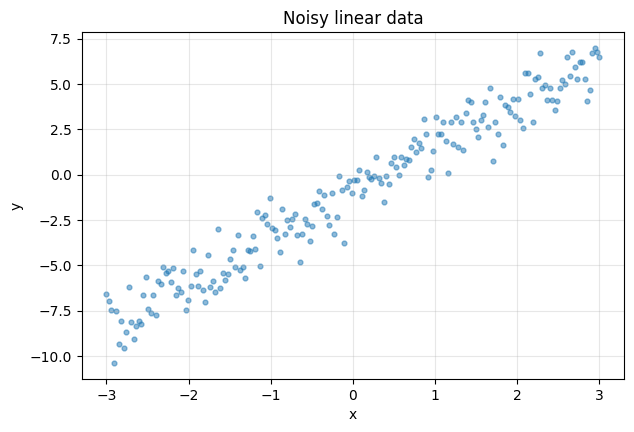

In [2]:
TRUE_W, TRUE_B = 2.5, -1.0

x = torch.linspace(-3, 3, 200, device=device).unsqueeze(1)   # (200, 1)
y = TRUE_W * x + TRUE_B + torch.randn(200, 1, device=device) * 1.0

plt.figure(figsize=(7, 4.5))
plt.scatter(x.cpu(), y.cpu(), s=12, alpha=0.5)
plt.xlabel("x"); plt.ylabel("y"); plt.title("Noisy linear data"); plt.grid(alpha=0.3)
plt.show()

We hold out the last 20% as a validation set — habit-building, even though for
this tiny linear problem train and val track each other closely.

In [3]:
n_val = 40
x_train, y_train = x[:-n_val], y[:-n_val]
x_val,   y_val   = x[-n_val:], y[-n_val:]
x_train.shape, x_val.shape

(torch.Size([160, 1]), torch.Size([40, 1]))

## 2. Model, loss, optimizer

`nn.Linear(1, 1)` holds two learnable parameters: a `weight` (the slope) and a
`bias` (the intercept). At init they're random — watch them move toward the truth.

In [4]:
model = nn.Linear(1, 1).to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)

print("initial w:", model.weight.item(), " b:", model.bias.item())

initial w: 0.14465749263763428  b: -0.2589707374572754


## 3. The training loop

Five steps, every epoch — this is the skeleton for **every** model you'll train:

1. **forward** — predictions from inputs
2. **loss** — one scalar measuring error
3. **`zero_grad`** — clear old gradients (PyTorch *accumulates* them by default)
4. **`backward`** — autograd computes `∂loss/∂param` into `param.grad`
5. **`step`** — optimizer nudges params down the gradient

In [5]:
EPOCHS = 300
train_losses, val_losses = [], []

for epoch in range(1, EPOCHS + 1):
    model.train()
    y_pred = model(x_train)            # 1. forward
    loss = loss_fn(y_pred, y_train)    # 2. loss

    optimizer.zero_grad()             # 3. reset grads
    loss.backward()                   # 4. backprop
    optimizer.step()                  # 5. update

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(x_val), y_val)

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

    if epoch % 30 == 0 or epoch == 1:
        print(f"epoch {epoch:4d} | train {loss.item():.4f} | val {val_loss.item():.4f}")

epoch    1 | train 16.2374 | val 13.9311
epoch   30 | train 0.9695 | val 0.9560
epoch   60 | train 0.9689 | val 0.9855
epoch   90 | train 0.9689 | val 0.9884
epoch  120 | train 0.9689 | val 0.9886
epoch  150 | train 0.9689 | val 0.9887
epoch  180 | train 0.9689 | val 0.9887
epoch  210 | train 0.9689 | val 0.9887
epoch  240 | train 0.9689 | val 0.9887
epoch  270 | train 0.9689 | val 0.9887
epoch  300 | train 0.9689 | val 0.9887


## 4. Loss curve

The loss flattens out **near ~1.0, not 0**. That floor is the irreducible noise:
the data has variance σ²=1.0 and no line can fit randomness. The model is doing
as well as is possible.

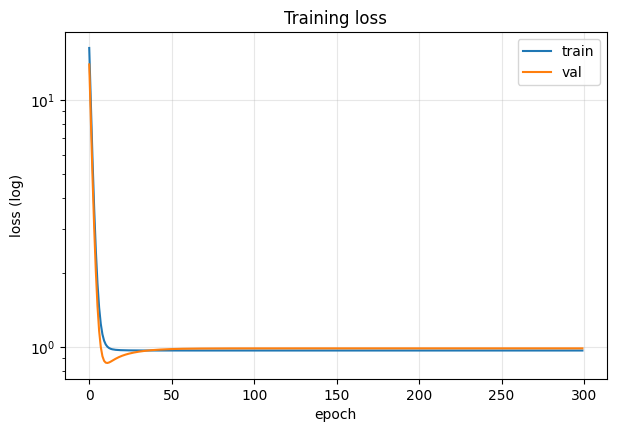

In [6]:
plt.figure(figsize=(7, 4.5))
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="val")
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("loss (log)"); plt.title("Training loss")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 5. The fit, and recovered parameters

learned  w=+2.5285  b=-0.8825
true     w=+2.5000  b=-1.0000


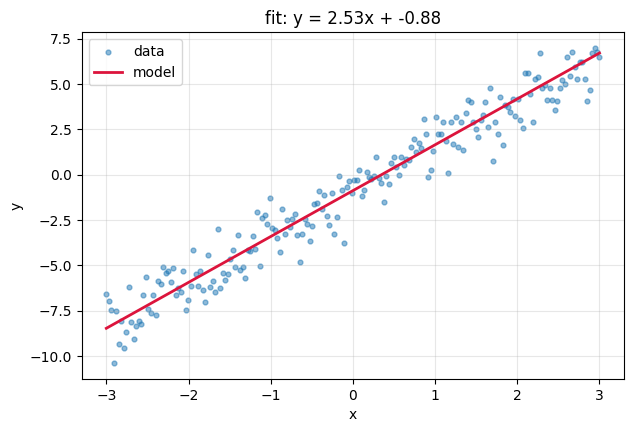

In [7]:
w, b = model.weight.item(), model.bias.item()
print(f"learned  w={w:+.4f}  b={b:+.4f}")
print(f"true     w={TRUE_W:+.4f}  b={TRUE_B:+.4f}")

with torch.no_grad():
    x_line = torch.linspace(-3, 3, 100, device=device).unsqueeze(1)
    y_line = model(x_line)

plt.figure(figsize=(7, 4.5))
plt.scatter(x.cpu(), y.cpu(), s=12, alpha=0.5, label="data")
plt.plot(x_line.cpu(), y_line.cpu(), color="crimson", lw=2, label="model")
plt.xlabel("x"); plt.ylabel("y"); plt.title(f"fit: y = {w:.2f}x + {b:.2f}")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Takeaways

- A **linear layer is linear regression** — nothing more mysterious going on.
- Loss plateaus at the **noise floor**, not zero. You fit signal, not noise.
- The **five-step loop** generalizes to every later experiment.
- This model **cannot fit a curve** — that's the motivation for the sine-wave
  experiment, where you'll need a hidden layer and a nonlinearity.

**Try it:** set the noise to 0 (loss → 0, exact recovery); crank `lr` to 0.5
(faster), then higher until it diverges.